In [ ]:
import marimo as mo

# Bank Marketing Data Mining

## Bank Marketing Dataset

Dataset sobre campañas de marketing de un banco Portugues. Las campañas de marketing se basan en llamadas telefonicas, cada registro representa un cliente e informacion sobre la campaña de marketing (se puede repetir el cliente debido a que en algunos casos se contactaron varias veces al mismo cliente).

UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)

- Numero de registros: 45,211
- Numero de caracteristicas: 16
- Variable ojetivo: `y` (Representa si un cliente se suscribio/contrato o no a un deposito a plazo fijo).

| Nombre Variable | Descripcion |
| --- | --- |
| `age` | Edad del cliente, en años. |
| `job` | Tipo de trabajo u ocupación: admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed o unknown. |
| `marital` | Estado civil: divorced, married, single o unknown. `divorced` también incluye a personas viudas. |
| `education` | Nivel educativo: primary, secondary o tertiary; algunos registros no lo reportan. |
| `default` | Indica si el cliente tiene crédito en mora (yes/no). |
| `balance` | Saldo anual promedio del cliente, en euros. |
| `housing` | Indica si el cliente tiene un préstamo hipotecario (yes/no). |
| `loan` | Indica si el cliente tiene un préstamo personal (yes/no). |
| `contact` | Tipo de medio de contacto: telephone o cellular; algunos registros no lo reportan. |
| `day_of_week` | Día del mes del último contacto de esta campaña (nombre conservado de la fuente). |
| `month` | Mes del último contacto de esta campaña (jan–dec). |
| `duration` | Duración del último contacto, en segundos. |
| `campaign` | Número de contactos realizados durante esta campaña para este cliente, incluido el último contacto. |
| `pdays` | Días desde el último contacto del cliente en una campaña anterior; `-1` indica que no había sido contactado anteriormente. |
| `previous` | Número de contactos realizados para este cliente antes de esta campaña. |
| `poutcome` | Resultado de la campaña anterior: other, failure o success; los faltantes indican que no se registró resultado previo. |
| `y` | Variable objetivo: indica si el cliente suscribió un depósito a plazo fijo (yes/no). |

## Planeamiento del Problema

El banco realiza campañas de marketing telefónico para ofrecer depósitos a plazo fijo. Como contactar a los clientes requiere recursos y, en algunos casos, varios intentos, es útil identificar de antemano cuáles tienen mayor probabilidad de aceptar la oferta. El problema consiste en utilizar la información de los clientes y de las campañas anteriores para predecir si un cliente suscribirá el depósito, resultado representado por la variable y (yes o no).

**Objetivo**: Desarrollar y evaluar un modelo de clasificación que, utilizando las variables disponibles del conjunto de datos Bank Marketing, prediga si un cliente suscribirá un depósito a plazo fijo.

## 0. Importacion de Librerias

In [ ]:
# Se importan las librerías para manipular datos, graficar y entrenar el modelo.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from scipy.stats import chi2_contingency, pearsonr
from ucimlrepo import fetch_ucirepo

## 1. Carga de Dataset

In [ ]:
# Se descarga la versión original del repositorio UCI para conservar
# los nombres y valores reportados por la fuente.
bank_marketing = fetch_ucirepo(id=222) 

# Se separan las variables explicativas y la respuesta por claridad.
X = bank_marketing.data.features 
y = bank_marketing.data.targets 

print(f"Registros cargados: {X.shape[0]:,}; variables predictoras: {X.shape[1]}")

Registros cargados: 45,211; variables predictoras: 16


In [ ]:
# Se revisa la forma y las primeras filas para confirmar una carga correcta.
print(f'X Shape: {X.shape}')
X.head()

X Shape: (45211, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN


In [ ]:
# Se comprueba que la variable objetivo tenga una sola columna y valores esperados.
print(f'y Shape: {y.shape}')
y.head()

y Shape: (45211, 1)


,y
0,no
1,no
2,no
3,no
4,no


## 2. Diagnostico de Calidad de los Datos

Identificar valores faltantes, duplicados, inconsistencias y valores atípicos.

In [ ]:
# Se integra la respuesta con los predictores para diagnosticar el conjunto completo.
datos_brutos = pd.concat([X.copy(), y.copy()], axis=1)
datos_brutos.columns = [str(col).strip() for col in datos_brutos.columns]

In [ ]:
# Se resumen tipos, faltantes, duplicados y cardinalidad de cada variable.
resumen_calidad = pd.DataFrame(
    {
        "tipo": datos_brutos.dtypes.astype(str),
        "faltantes": datos_brutos.isna().sum(),
        "porcentaje_faltante": (datos_brutos.isna().mean() * 100).round(2),
        "valores_unicos": datos_brutos.nunique(),
    }
)
duplicados_brutos = int(datos_brutos.duplicated().sum())
print(f"Filas duplicadas completas: {duplicados_brutos:,}")
resumen_calidad

Filas duplicadas completas: 0


,tipo,faltantes,porcentaje_faltante,valores_unicos
age,int64,0,0.00,77
job,str,288,0.64,11
marital,str,0,0.00,3
education,str,1857,4.11,3
default,str,0,0.00,2
...,...,...,...,...
campaign,int64,0,0.00,48
pdays,int64,0,0.00,559
previous,int64,0,0.00,41
poutcome,str,36959,81.75,3


In [ ]:
# Se inspeccionan faltantes y valores especiales documentados por la fuente.
columnas_texto = datos_brutos.select_dtypes(include=["object", "string"]).columns
conteo_faltantes_categoricos = pd.DataFrame(
    {
        "faltantes": [
            datos_brutos[col].isna().sum()
            for col in columnas_texto
        ]
    },
    index=columnas_texto,
)
print(
    "Registros con pdays = -1 (sin contacto previo): "
    f"{(datos_brutos['pdays'] == -1).sum():,}"
)
conteo_faltantes_categoricos

Registros con pdays = -1 (sin contacto previo): 36,954


,faltantes
job,288
marital,0
education,1857
default,0
housing,0
loan,0
contact,13020
month,0
poutcome,36959
y,0


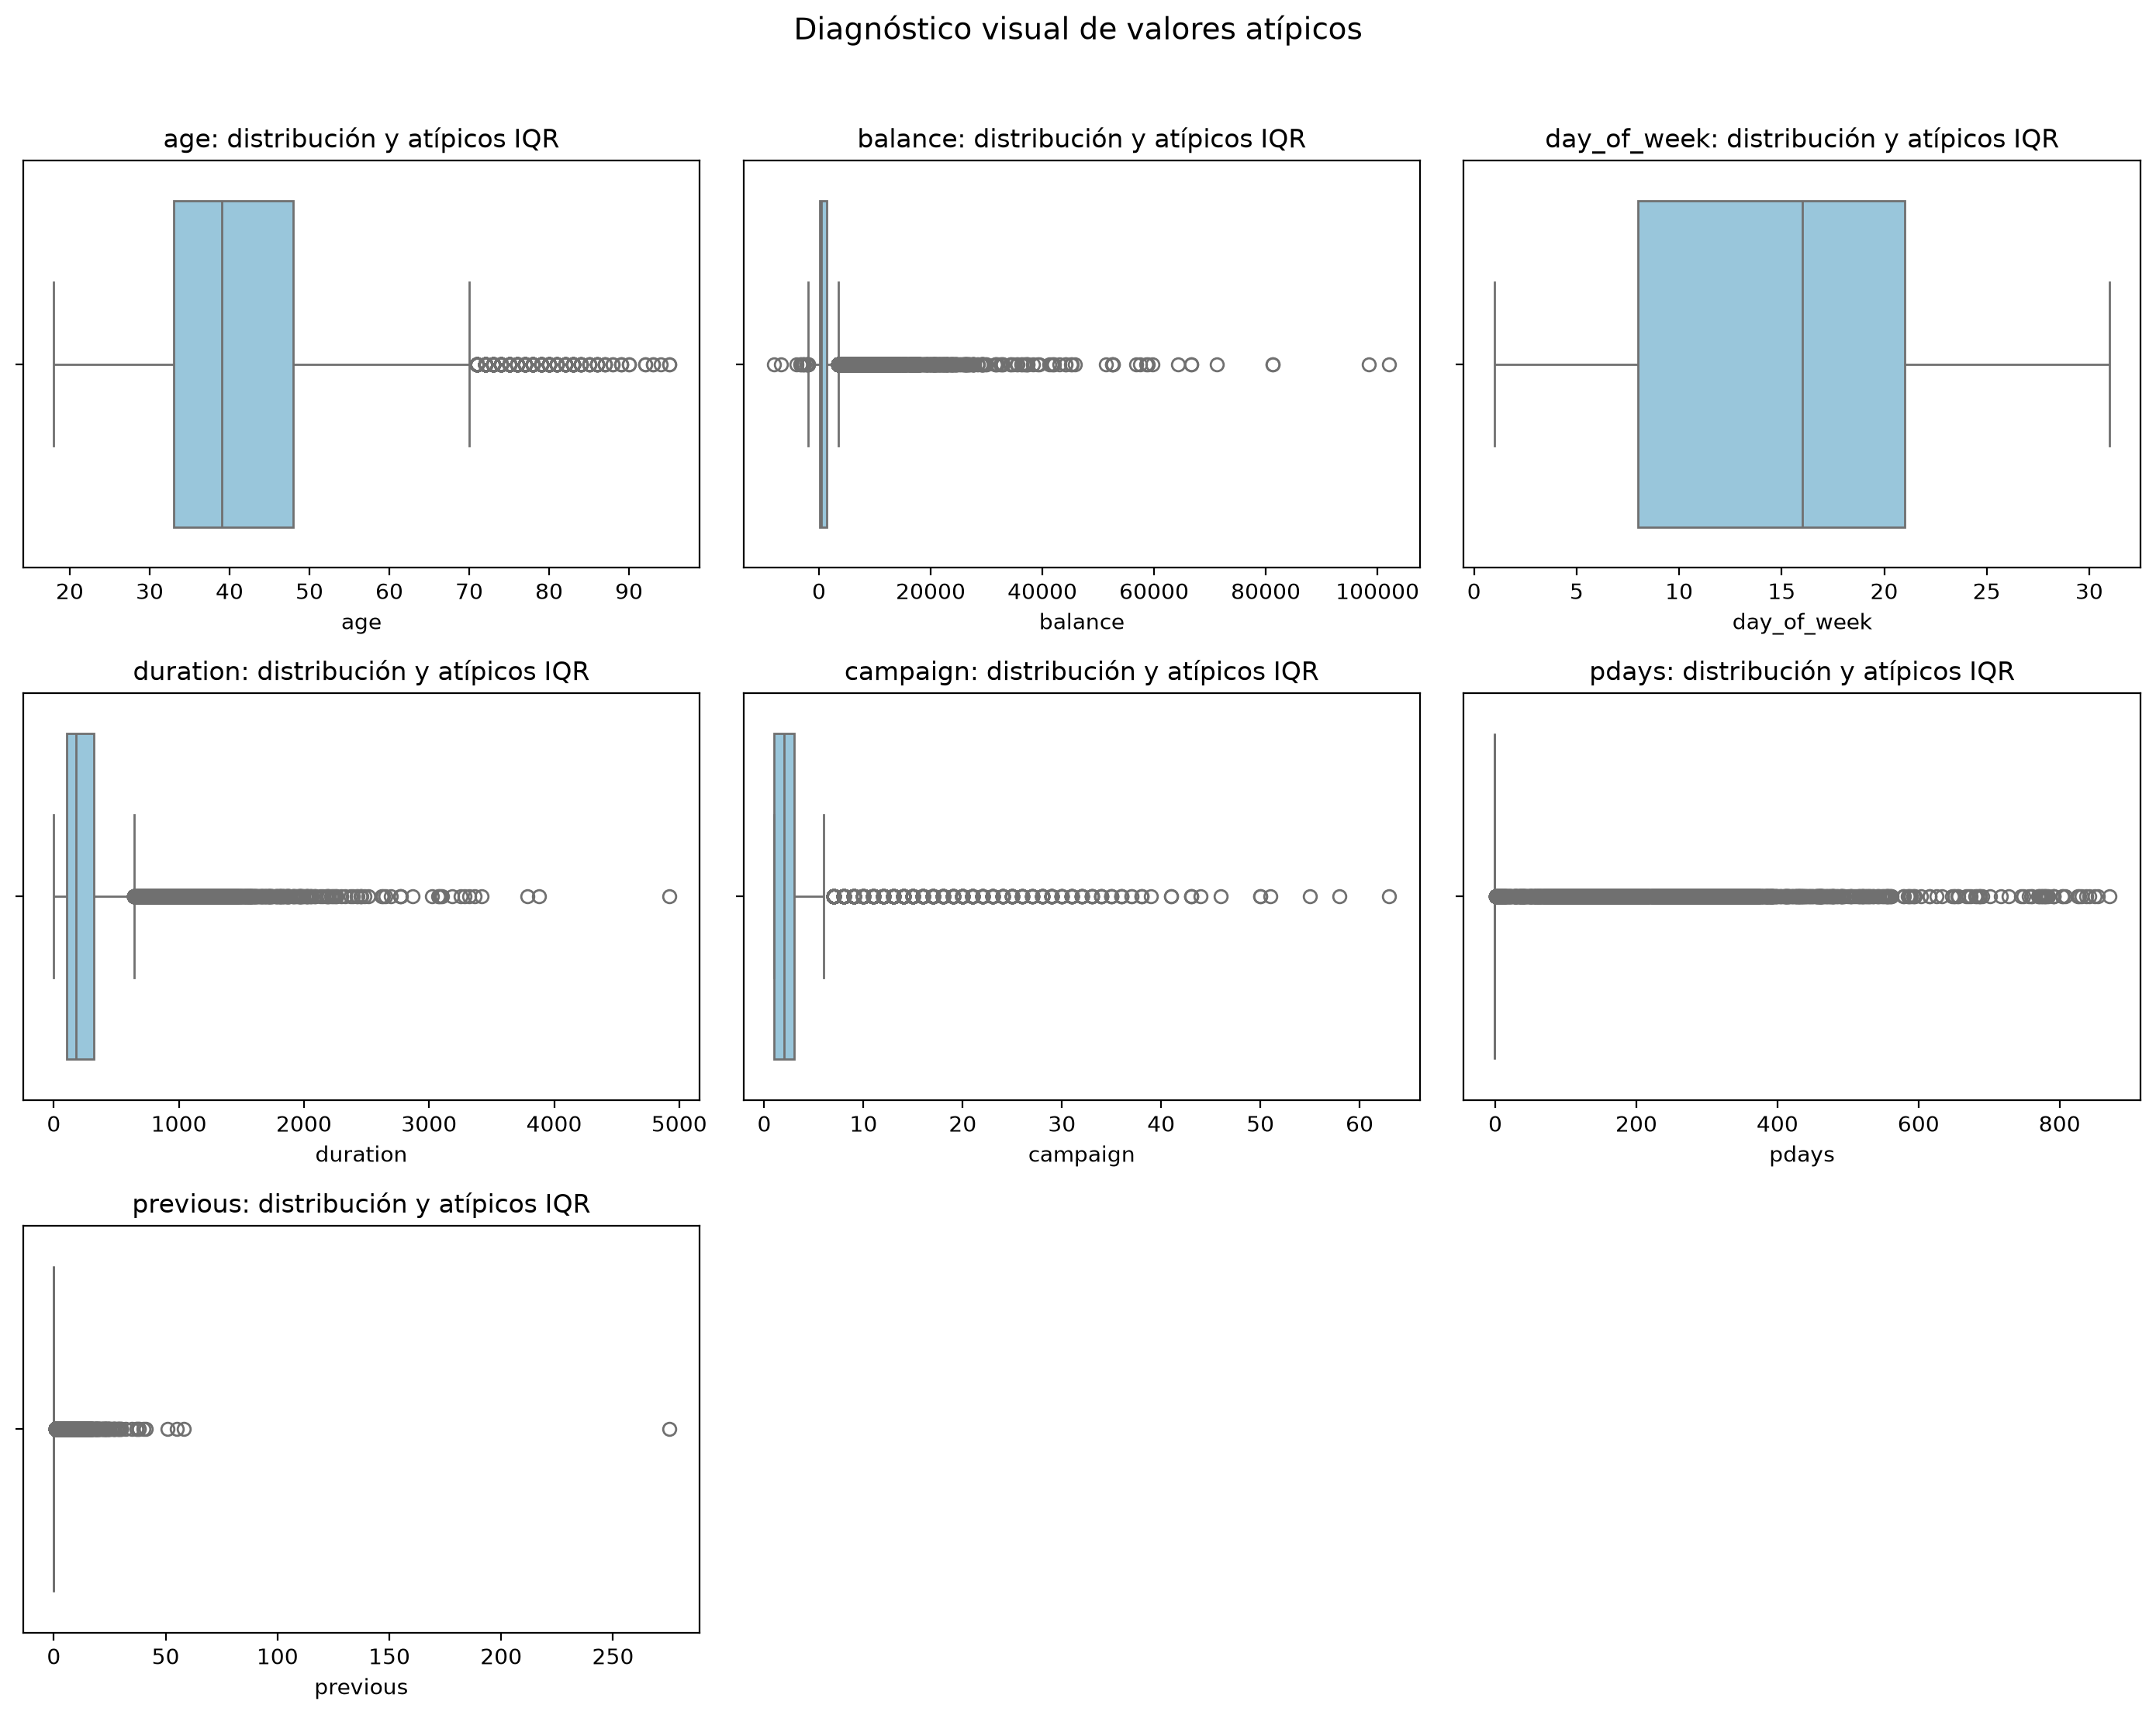

,q1,q3,iqr,limite_inferior,limite_superior,valores_atipicos_iqr
age,33.0,48.0,15.0,10.5,70.5,487
balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729
day_of_week,8.0,21.0,13.0,-11.5,40.5,0
duration,103.0,319.0,216.0,-221.0,643.0,3235
campaign,1.0,3.0,2.0,-2.0,6.0,3064
pdays,-1.0,-1.0,0.0,-1.0,-1.0,8257
previous,0.0,0.0,0.0,0.0,0.0,8257


In [ ]:
# IQR se usa como señal de revisión, no como regla automática de eliminación.
_columnas_numericas_diagnostico = datos_brutos.select_dtypes(include="number").columns.tolist()
_cuantiles = datos_brutos[_columnas_numericas_diagnostico].quantile([0.25, 0.75]).T
_cuantiles.columns = ["q1", "q3"]
_cuantiles["iqr"] = _cuantiles["q3"] - _cuantiles["q1"]
_cuantiles["limite_inferior"] = _cuantiles["q1"] - 1.5 * _cuantiles["iqr"]
_cuantiles["limite_superior"] = _cuantiles["q3"] + 1.5 * _cuantiles["iqr"]
_conteo_atipicos = pd.DataFrame(
    {
        "valores_atipicos_iqr": [
            int(
                (
                    (datos_brutos[_col] < _cuantiles.loc[_col, "limite_inferior"])
                    | (datos_brutos[_col] > _cuantiles.loc[_col, "limite_superior"])
                ).sum()
            )
            for _col in _columnas_numericas_diagnostico
        ]
    },
    index=_columnas_numericas_diagnostico,
)
diagnostico_atipicos = _cuantiles.join(_conteo_atipicos).round(2)

_n_columnas = 3
_n_filas = int(np.ceil(len(_columnas_numericas_diagnostico) / _n_columnas))
_fig_atipicos, _ejes_atipicos = plt.subplots(_n_filas, _n_columnas, figsize=(14, 3.6 * _n_filas))
for _eje, _columna in zip(_ejes_atipicos.flat, _columnas_numericas_diagnostico):
    sns.boxplot(x=datos_brutos[_columna], ax=_eje, color="#8ecae6")
    _eje.set_title(f"{_columna}: distribución y atípicos IQR")
    _eje.set_xlabel(_columna)
for _eje in _ejes_atipicos.flat[len(_columnas_numericas_diagnostico):]:
    _eje.set_visible(False)
_fig_atipicos.suptitle("Diagnóstico visual de valores atípicos", y=1.02, fontsize=14)
_fig_atipicos.tight_layout()
plt.show()
diagnostico_atipicos

In [ ]:
# Se comparan las categorías observadas con los dominios documentados después de normalizar texto.
_dominios_esperados = {
    "job": {"admin.", "blue-collar", "entrepreneur", "housemaid", "management", "retired", "self-employed", "services", "student", "technician", "unemployed"},
    "marital": {"divorced", "married", "single"},
    "education": {"primary", "secondary", "tertiary"},
    "default": {"no", "yes"},
    "housing": {"no", "yes"},
    "loan": {"no", "yes"},
    "contact": {"cellular", "telephone"},
    "month": {"jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"},
    "poutcome": {"failure", "other", "success"},
    "y": {"no", "yes"},
}
_filas_consistencia = []
for _columna, _dominio in _dominios_esperados.items():
    _valores = datos_brutos[_columna].astype("string").str.strip().str.lower()
    _observadas = set(_valores.dropna().unique())
    _inesperadas = sorted(_observadas.difference(_dominio))
    _filas_consistencia.append(
        {
            "variable": _columna,
            "categorias_observadas": ", ".join(sorted(_observadas)),
            "faltantes": int(_valores.isna().sum()),
            "blancos": int(_valores.eq("").sum()),
            "categorias_inesperadas": ", ".join(_inesperadas) if _inesperadas else "ninguna",
            "resultado": "dominio consistente" if not _inesperadas and not _valores.eq("").any() else "requiere revisión",
        }
    )
consistencia_categoricas = pd.DataFrame(_filas_consistencia)
consistencia_categoricas

,variable,categorias_observadas,faltantes,blancos,categorias_inesperadas,resultado
0,job,"admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed",288,0,ninguna,dominio consistente
1,marital,"divorced, married, single",0,0,ninguna,dominio consistente
2,education,"primary, secondary, tertiary",1857,0,ninguna,dominio consistente
3,default,"no, yes",0,0,ninguna,dominio consistente
4,housing,"no, yes",0,0,ninguna,dominio consistente
5,loan,"no, yes",0,0,ninguna,dominio consistente
6,contact,"cellular, telephone",13020,0,ninguna,dominio consistente
7,month,"apr, aug, dec, feb, jan, jul, jun, mar, may, nov, oct, sep",0,0,ninguna,dominio consistente
8,poutcome,"failure, other, success",36959,0,ninguna,dominio consistente
9,y,"no, yes",0,0,ninguna,dominio consistente


**Interpretación del diagnóstico.** Las marcas IQR y los puntos extremos de los diagramas de caja
identifican observaciones que merecen revisión, pero no son por sí mismos errores. En marketing
bancario, saldos elevados, muchos contactos o intervalos largos entre campañas pueden describir
clientes reales; eliminarlos sin evidencia cambiaría artificialmente la población objetivo. Por
ello se conservarán los valores numéricos y se aplicará escalamiento robusto a la escala de cada
variable. La tabla de consistencia permite confirmar que, una vez retirados espacios, las
categorías están dentro de los dominios documentados. Los faltantes de las categóricas no se
eliminan: se imputarán con la moda dentro del pipeline para no perder registros. `pdays = -1`
se mantiene porque expresa ausencia de contacto previo y puede ser predictivo.

## 3. Limpieza de Datos

La limpieza conserva la información de negocio y corrige solamente problemas verificables de formato
o duplicación. La siguiente tabla deja trazabilidad de cada decisión antes de ejecutarla.

| Problema identificado | Variables | Decisión | Justificación |
| --- | --- | --- | --- |
| Filas duplicadas exactas | Todas | Eliminar solo registros idénticos en todas las columnas | Evita sobreponderar una misma observación sin eliminar llamadas distintas de un cliente. |
| Espacios o diferencias de formato | Categóricas y objetivo | Recortar espacios y homogeneizar a minúsculas al evaluar dominios | Previene categorías duplicadas por captura; no altera su significado. |
| Faltantes categóricos | `job`, `education`, `contact`, `poutcome` | Imputar con la moda dentro del pipeline | Conserva registros y evita que estadísticos del conjunto de prueba influyan en entrenamiento. |
| `pdays = -1` | `pdays` | Conservar el valor | La documentación lo define como ausencia de contacto previo, no como dato faltante. |
| Valores atípicos IQR | Numéricas | Conservar y escalar; no truncar | No hay evidencia de error y los extremos pueden ser clientes o campañas reales. |
| Faltantes futuros | Numéricas y categóricas | Imputar dentro del pipeline de entrenamiento | Mantiene el flujo reproducible y evita fuga de información. |

In [ ]:
# Se eliminan solo duplicados exactos. No se eliminan clientes repetidos porque cada llamada
# puede corresponder a un intento distinto y aporta información de campaña.
datos_limpios = datos_brutos.drop_duplicates().copy()

# Se normalizan espacios en variables de texto para evitar categorías duplicadas por formato.
columnas_texto_limpias = datos_limpios.select_dtypes(include=["object", "string"]).columns
for _columna in columnas_texto_limpias:
    datos_limpios[_columna] = datos_limpios[_columna].str.strip().str.lower()

# La imputación posterior queda dentro para no filtrar información del conjunto de prueba.
print(f"Registros eliminados por duplicado: {duplicados_brutos:,}")
print(f"Registros disponibles después de limpiar: {len(datos_limpios):,}")

Registros eliminados por duplicado: 0
Registros disponibles después de limpiar: 45,211


## 4. Transformación de Variables y 5. Ingeniería de características

Las transformaciones se definen antes de ejecutarse para distinguir los datos disponibles al
momento de priorizar una llamada de los datos que solo se conocen después. La imputación, el
escalamiento y la codificación se ajustan únicamente dentro del entrenamiento.

| Variable | Tipo de variable | Transformación propuesta | Justificación |
| --- | --- | --- | --- |
| `age` | Numérica | Mediana y MinMax | Atenúa el efecto de una escala distinta y mantiene valores no negativos. |
| `job` | Categórica nominal | Moda y one-hot | No existe un orden natural entre ocupaciones. |
| `marital` | Categórica nominal | Moda y one-hot | Representa estados sin jerarquía cuantitativa. |
| `education` | Categórica ordinal aproximada | Moda y one-hot | Evita imponer distancias arbitrarias entre niveles educativos. |
| `default` | Categórica binaria | Moda y one-hot | Conserva la interpretación sí/no. |
| `balance` | Numérica | Mediana y MinMax | Conserva la señal del saldo en una escala comparable. |
| `housing` | Categórica binaria | Moda y one-hot | Conserva el indicador de crédito hipotecario. |
| `loan` | Categórica binaria | Moda y one-hot | Conserva el indicador de crédito personal. |
| `contact` | Categórica nominal | Moda y one-hot | Los canales no tienen orden intrínseco. |
| `day_of_week` | Numérica discreta | Mediana y MinMax | Mantiene el momento mensual sin crear una jerarquía categórica. |
| `month` | Categórica temporal | Moda y one-hot | Permite patrones estacionales sin asumir distancia lineal entre meses. |
| `duration` | Numérica | Excluir | Solo se conoce al terminar la llamada; incluirla causaría fuga de información. |
| `campaign` | Numérica discreta | Mediana y MinMax y derivada | Resume la presión actual de contacto. |
| `pdays` | Numérica con código especial | Mediana y MinMax; conservar `-1` | El código identifica explícitamente falta de contacto previo. |
| `previous` | Numérica discreta | Mediana y MinMax y derivada | Aporta historial de campañas anteriores. |
| `poutcome` | Categórica nominal | Moda y one-hot | El resultado previo puede tener asociación con la suscripción. |
| `presion_contacto` | Numérica derivada | `campaign / (previous + 1)` y MinMax | Contrasta insistencia actual con historial previo, sin dividir entre cero. |
| `balance_ajustado_credito` | Numérica derivada | `balance / (1 + housing + loan)` y MinMax | Aproxima el saldo disponible considerando créditos reportados. |
| `y` | Objetivo binario | `yes` a 1 y `no` a 0 | Permite estimar una probabilidad de suscripción. |

In [ ]:
# Se crean exactamente dos variables derivadas mediante operaciones entre columnas existentes.
# Ambas están disponibles antes de hacer una llamada y no usan la variable objetivo.
datos_modelo = datos_limpios.copy()

# Relaciona los contactos de la campaña actual con los de campañas previas.
# Un valor alto señala insistencia reciente; un valor bajo indica más historial que presión actual.
datos_modelo["presion_contacto"] = datos_modelo["campaign"] / (
    datos_modelo["previous"] + 1
)

# Ajusta el saldo por la cantidad de créditos activos reportados (vivienda y personal).
# Sirve como aproximación de la capacidad financiera disponible para aceptar un depósito.
datos_modelo["balance_ajustado_credito"] = datos_modelo["balance"] / (
    1
    + datos_modelo["housing"].eq("yes").astype(int)
    + datos_modelo["loan"].eq("yes").astype(int)
)

# Se muestra un ejemplo para comprobar que las dos columnas sí fueron creadas.
print("Ejemplo de variables derivadas:")
print(
    datos_modelo[
        [
            "campaign",
            "previous",
            "presion_contacto",
            "balance",
            "housing",
            "loan",
            "balance_ajustado_credito",
        ]
    ].head()
)

# duration se excluye: se conoce al finalizar la llamada y no estaría disponible
# cuando el banco tenga que decidir a quién contactar. Incluirla inflaría el desempeño.
X_modelo = datos_modelo.drop(columns=["y", "duration"])
y_modelo = (datos_modelo["y"].str.lower() == "yes").astype(int)

print("Distribución de la respuesta (0 = no, 1 = sí):")
print(y_modelo.value_counts(normalize=True).rename("proporción").round(4))

Ejemplo de variables derivadas:
   campaign  previous  presion_contacto  balance housing loan  \
0         1         0               1.0     2143     yes   no   
1         1         0               1.0       29     yes   no   
2         1         0               1.0        2     yes  yes   
3         1         0               1.0     1506     yes   no   
4         1         0               1.0        1      no   no   

   balance_ajustado_credito  
0               1071.500000  
1                 14.500000  
2                  0.666667  
3                753.000000  
4                  1.000000  
Distribución de la respuesta (0 = no, 1 = sí):
y
0    0.883
1    0.117
Name: proporción, dtype: float64


In [ ]:
# Se identifican columnas por tipo para aplicar una preparación adecuada a cada grupo.
columnas_numericas = X_modelo.select_dtypes(include="number").columns.tolist()
columnas_categoricas = X_modelo.select_dtypes(exclude="number").columns.tolist()
print(f"Variables numéricas: {len(columnas_numericas)}")
print(f"Variables categóricas: {len(columnas_categoricas)}")

Variables numéricas: 8
Variables categóricas: 9


In [ ]:
# Las numéricas se imputan con mediana y se escalan a [0,1], condición necesaria para chi-cuadrada.
# Las categóricas se imputan con la moda y se convierten a indicadores mediante one-hot encoding.
transformador_numerico = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("escala", MinMaxScaler()),
    ]
)
transformador_categorico = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("codificacion", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", transformador_numerico, columnas_numericas),
        ("categoricas", transformador_categorico, columnas_categoricas),
    ],
    remainder="drop",
)

## 6. Partición del conjunto de datos en entrenamiento y prueba

Se reserva una muestra independiente antes de cualquier filtro. La estratificación mantiene en
entrenamiento y prueba la proporción de suscripciones, que es minoritaria, y permite que la
evaluación final represente la población original.

In [ ]:
# Se reserva 20% para una evaluación final independiente. La estratificación conserva
# la proporción de suscripciones en ambos subconjuntos, importante por el desbalance.
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X_modelo,
    y_modelo,
    test_size=0.20,
    random_state=42,
    stratify=y_modelo,
)
print(f"Entrenamiento: {X_entrenamiento.shape[0]:,} filas")
print(f"Prueba: {X_prueba.shape[0]:,} filas")

Entrenamiento: 36,168 filas
Prueba: 9,043 filas


## 7. Aplicación de métodos de filtro para la selección de características

Los filtros se calculan solo sobre entrenamiento. Cada variable descriptiva se contrasta con
`y`: chi-cuadrada para categóricas y Pearson para numéricas. Los puntajes miden asociaciones,
no causalidad, y sirven para priorizar variables que deben revisarse junto con el contexto de
negocio.

| Criterio | Chi-cuadrada | Pearson |
| --- | --- | --- |
| Variables analizadas | Categóricas frente al objetivo binario | Numéricas frente al objetivo binario codificado 0/1 |
| Evidencia reportada | Estadístico, p-valor y V de Cramér | Correlación `r`, p-valor y valor absoluto de `r` |
| Lectura del ranking | Mayor V de Cramér indica asociación categórica más fuerte | Mayor `abs(r)` indica asociación lineal más fuerte |
| Comparación entre filtros | No se comparan sus magnitudes directamente: usan escalas distintas. Se comparan las variables relevantes dentro de su propio tipo. | No se comparan sus magnitudes directamente: usan escalas distintas. Se comparan las variables relevantes dentro de su propio tipo. |

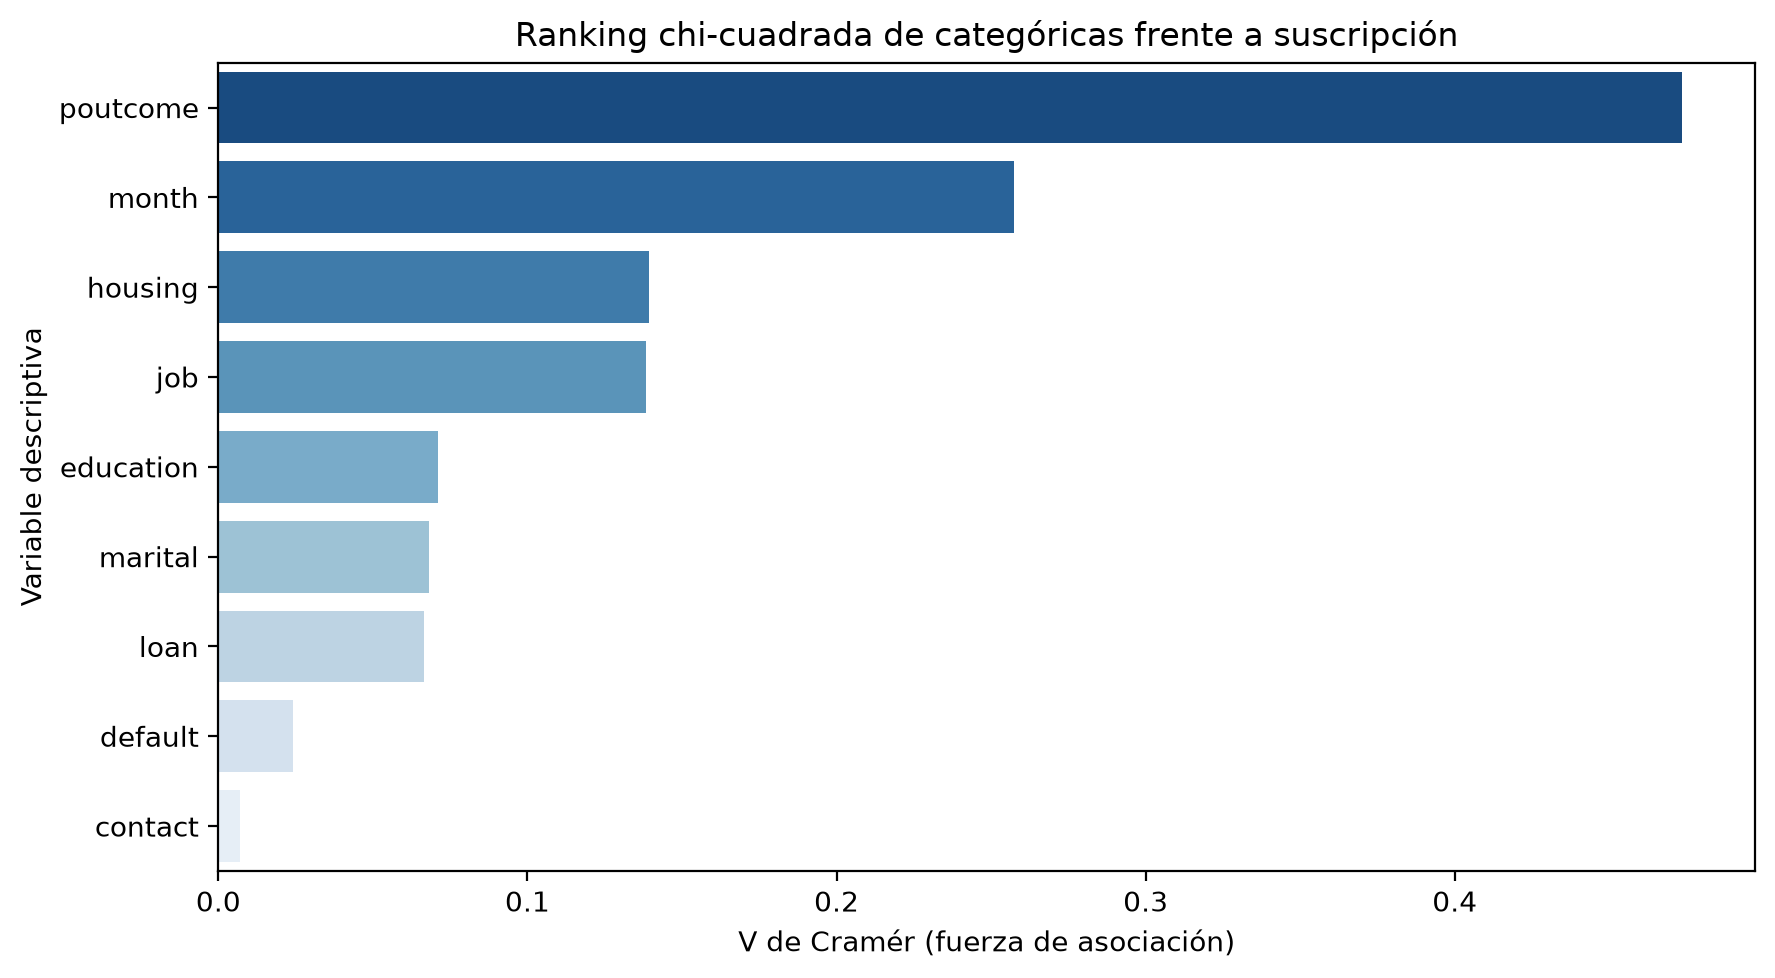

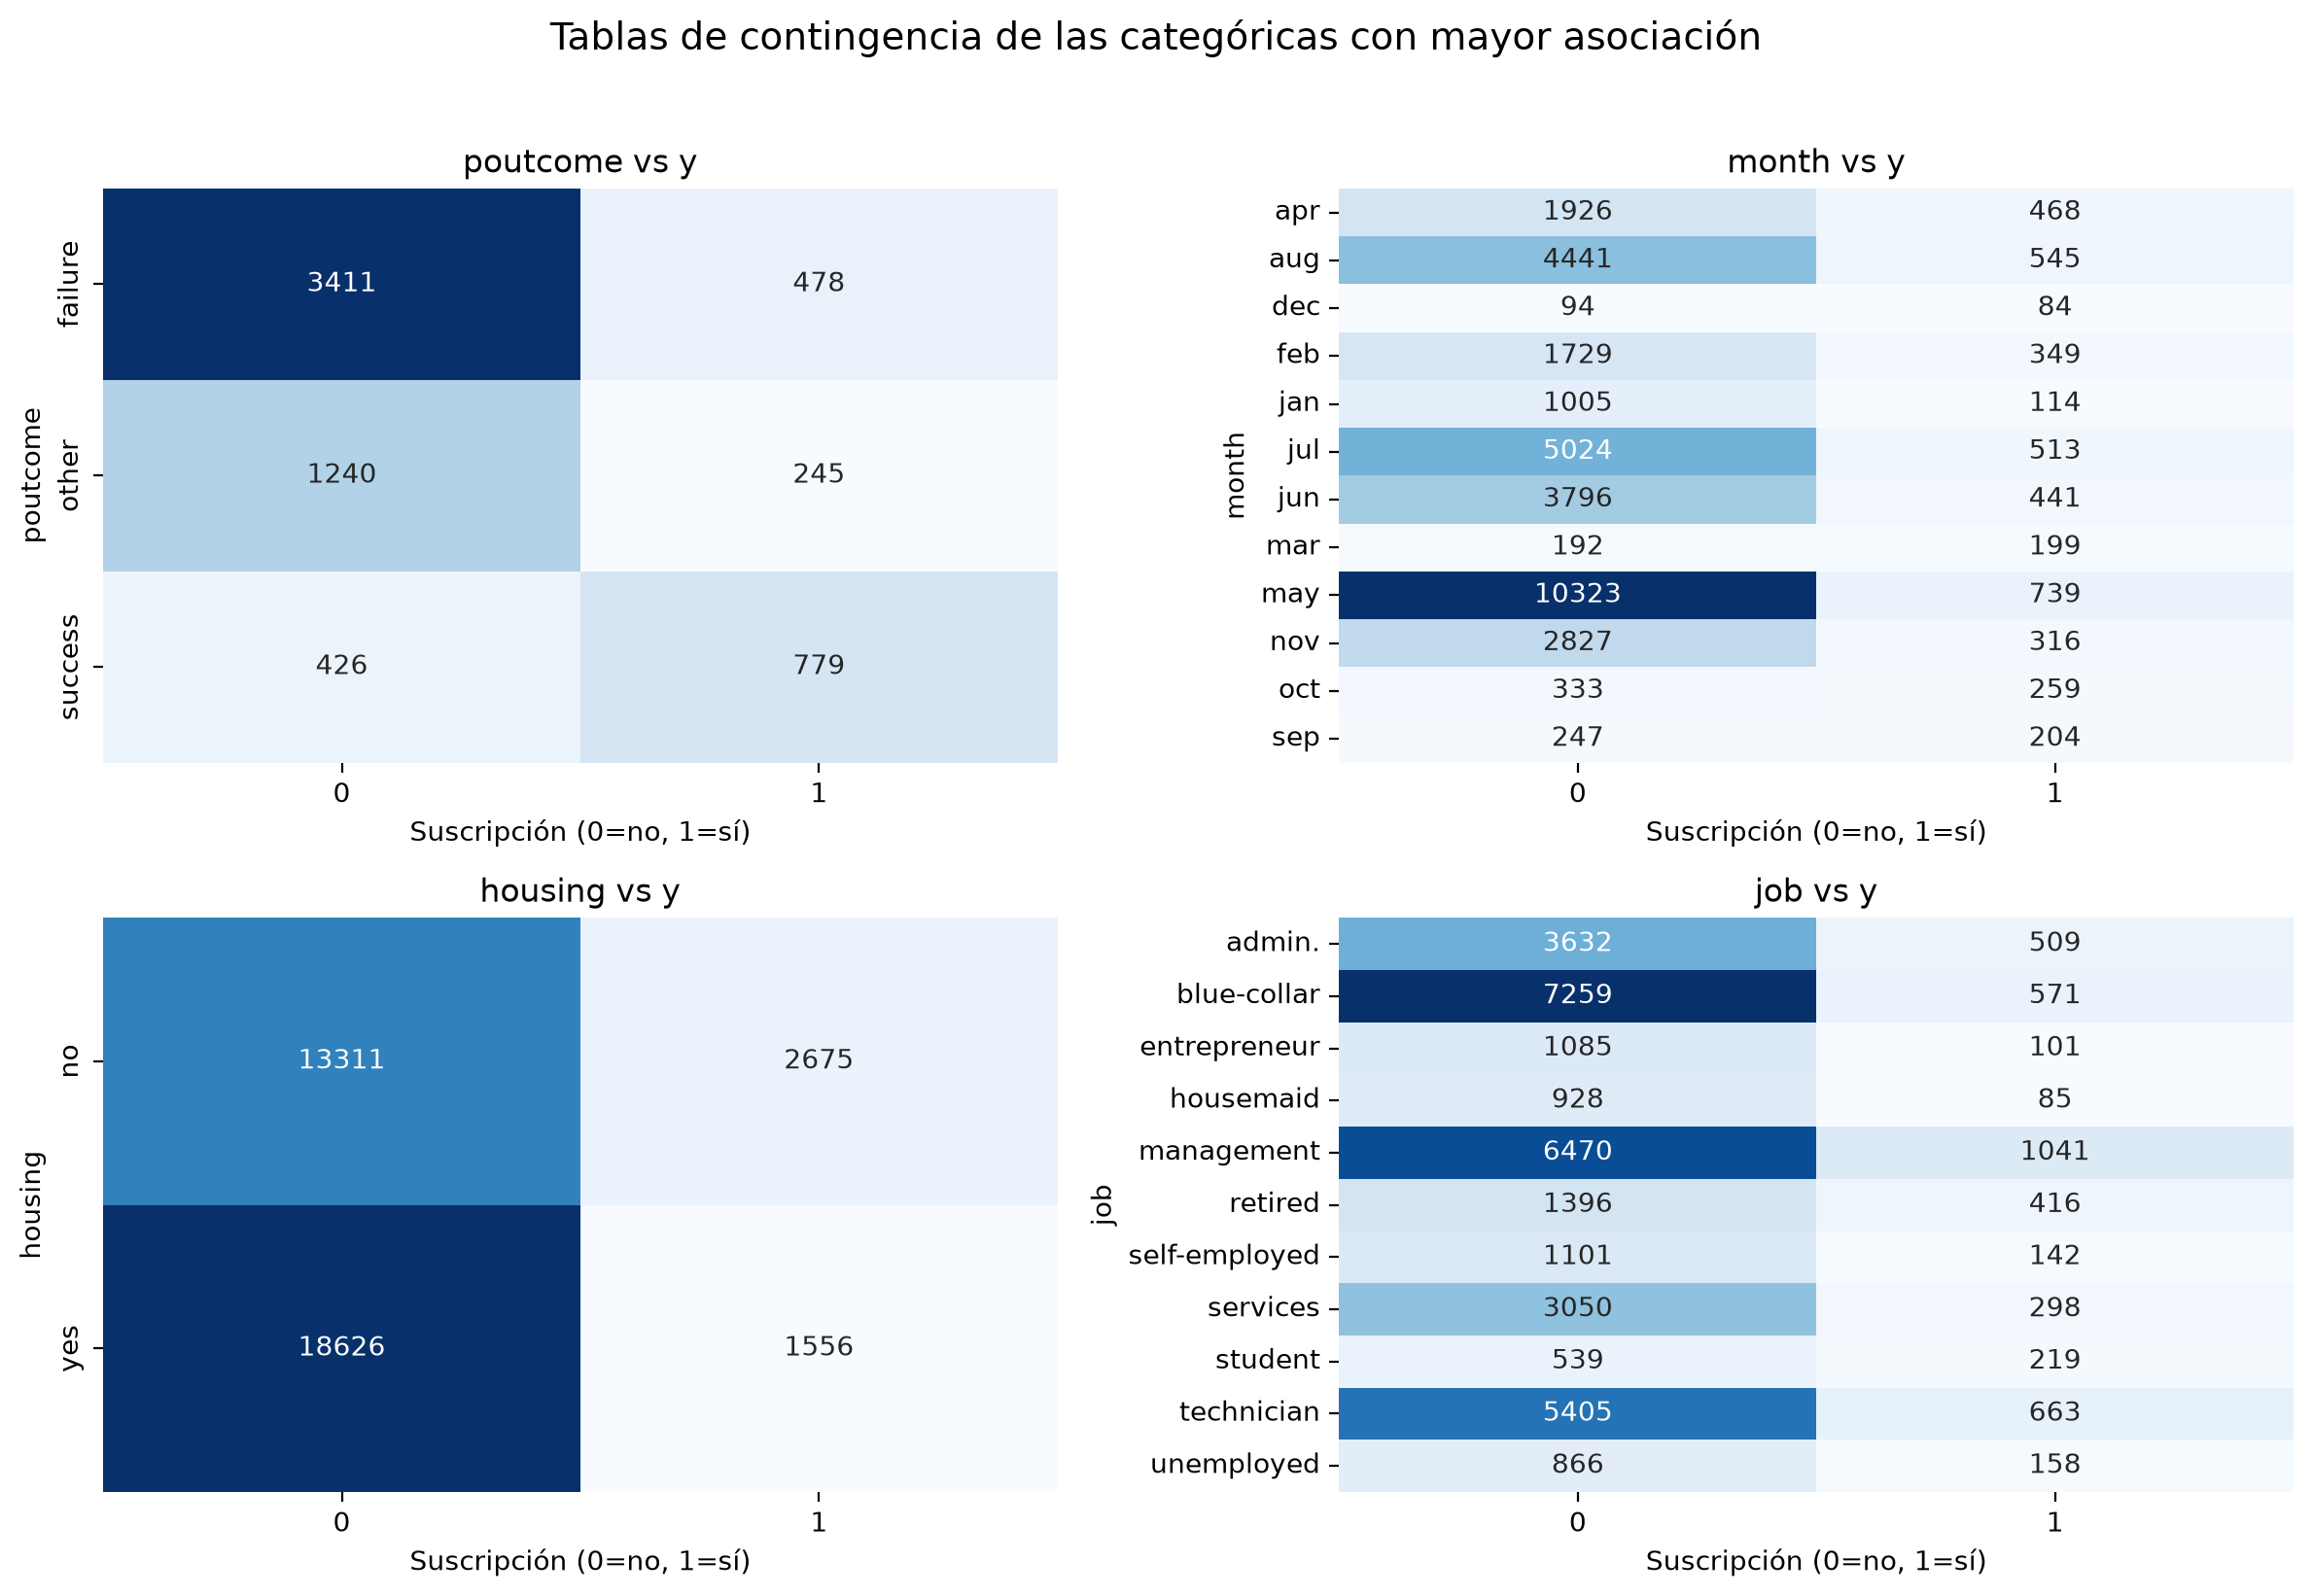

,variable,chi_cuadrada,p_valor,grados_libertad,v_cramer
0,poutcome,1474.9939,0.0000,2,0.4735
1,month,2395.2054,0.0000,11,0.2573
2,housing,702.2741,0.0000,1,0.1393
3,job,687.0442,0.0000,10,0.1383
4,education,174.3963,0.0000,2,0.0709
5,marital,168.0022,0.0000,2,0.0682
6,loan,159.4996,0.0000,1,0.0664
7,default,21.0686,0.0000,1,0.0241
8,contact,1.2711,0.2596,1,0.0070


In [ ]:
# Método 1: una tabla de contingencia por variable categórica frente a la respuesta.
_columnas_categoricas_filtro = X_entrenamiento.select_dtypes(exclude="number").columns
_resultados_chi = []
_tablas_contingencia = {}
for _columna in _columnas_categoricas_filtro:
    _tabla = pd.crosstab(X_entrenamiento[_columna], y_entrenamiento)
    _estadistico, _p_valor, _grados_libertad, _ = chi2_contingency(_tabla)
    _n = _tabla.to_numpy().sum()
    # V de Cramér permite comparar asociaciones con distinta cantidad de categorías.
    _minimo_dimension = min(_tabla.shape) - 1
    _v_cramer = (_estadistico / (_n * _minimo_dimension)) ** 0.5 if _minimo_dimension else 0.0
    _resultados_chi.append(
        {
            "variable": _columna,
            "chi_cuadrada": _estadistico,
            "p_valor": _p_valor,
            "grados_libertad": _grados_libertad,
            "v_cramer": _v_cramer,
        }
    )
    _tablas_contingencia[_columna] = _tabla
ranking_chi2 = (
    pd.DataFrame(_resultados_chi)
    .sort_values(["v_cramer", "chi_cuadrada"], ascending=False)
    .reset_index(drop=True)
)

_fig_ranking_chi, _eje_ranking_chi = plt.subplots(figsize=(9, 5))
sns.barplot(data=ranking_chi2, x="v_cramer", y="variable", hue="variable", legend=False, palette="Blues_r", ax=_eje_ranking_chi)
_eje_ranking_chi.set_title("Ranking chi-cuadrada de categóricas frente a suscripción")
_eje_ranking_chi.set_xlabel("V de Cramér (fuerza de asociación)")
_eje_ranking_chi.set_ylabel("Variable descriptiva")
_fig_ranking_chi.tight_layout()

_variables_chi_grafica = ranking_chi2.head(4)["variable"].tolist()
_fig_tablas_chi, _ejes_tablas_chi = plt.subplots(2, 2, figsize=(12, 8))
for _eje, _columna in zip(_ejes_tablas_chi.flat, _variables_chi_grafica):
    sns.heatmap(_tablas_contingencia[_columna], annot=True, fmt="d", cmap="Blues", cbar=False, ax=_eje)
    _eje.set_title(f"{_columna} vs y")
    _eje.set_xlabel("Suscripción (0=no, 1=sí)")
    _eje.set_ylabel(_columna)
_fig_tablas_chi.suptitle("Tablas de contingencia de las categóricas con mayor asociación", y=1.02, fontsize=14)
_fig_tablas_chi.tight_layout()
plt.show()
ranking_chi2.round(4)

In [ ]:
principal_chi = ranking_chi2.iloc[0]
mo.md(
    f"""
    **Interpretación de chi-cuadrada.** `{principal_chi['variable']}` presenta la mayor asociación
    categórica con la suscripción (V de Cramér = **{principal_chi['v_cramer']:.3f}**; p-valor =
    **{principal_chi['p_valor']:.3g}**). Las gráficas de contingencia muestran cómo se distribuyen
    los sí y no dentro de cada categoría. Las variables con p-valor bajo son candidatas a conservar,
    pero el tamaño de efecto evita confundir un resultado significativo por el gran tamaño muestral
    con una asociación sustantiva.
    """
)

**Interpretación de chi-cuadrada.** `poutcome` presenta la mayor asociación
categórica con la suscripción (V de Cramér = **0.473**; p-valor =
**0**). Las gráficas de contingencia muestran cómo se distribuyen
los sí y no dentro de cada categoría. Las variables con p-valor bajo son candidatas a conservar,
pero el tamaño de efecto evita confundir un resultado significativo por el gran tamaño muestral
con una asociación sustantiva.

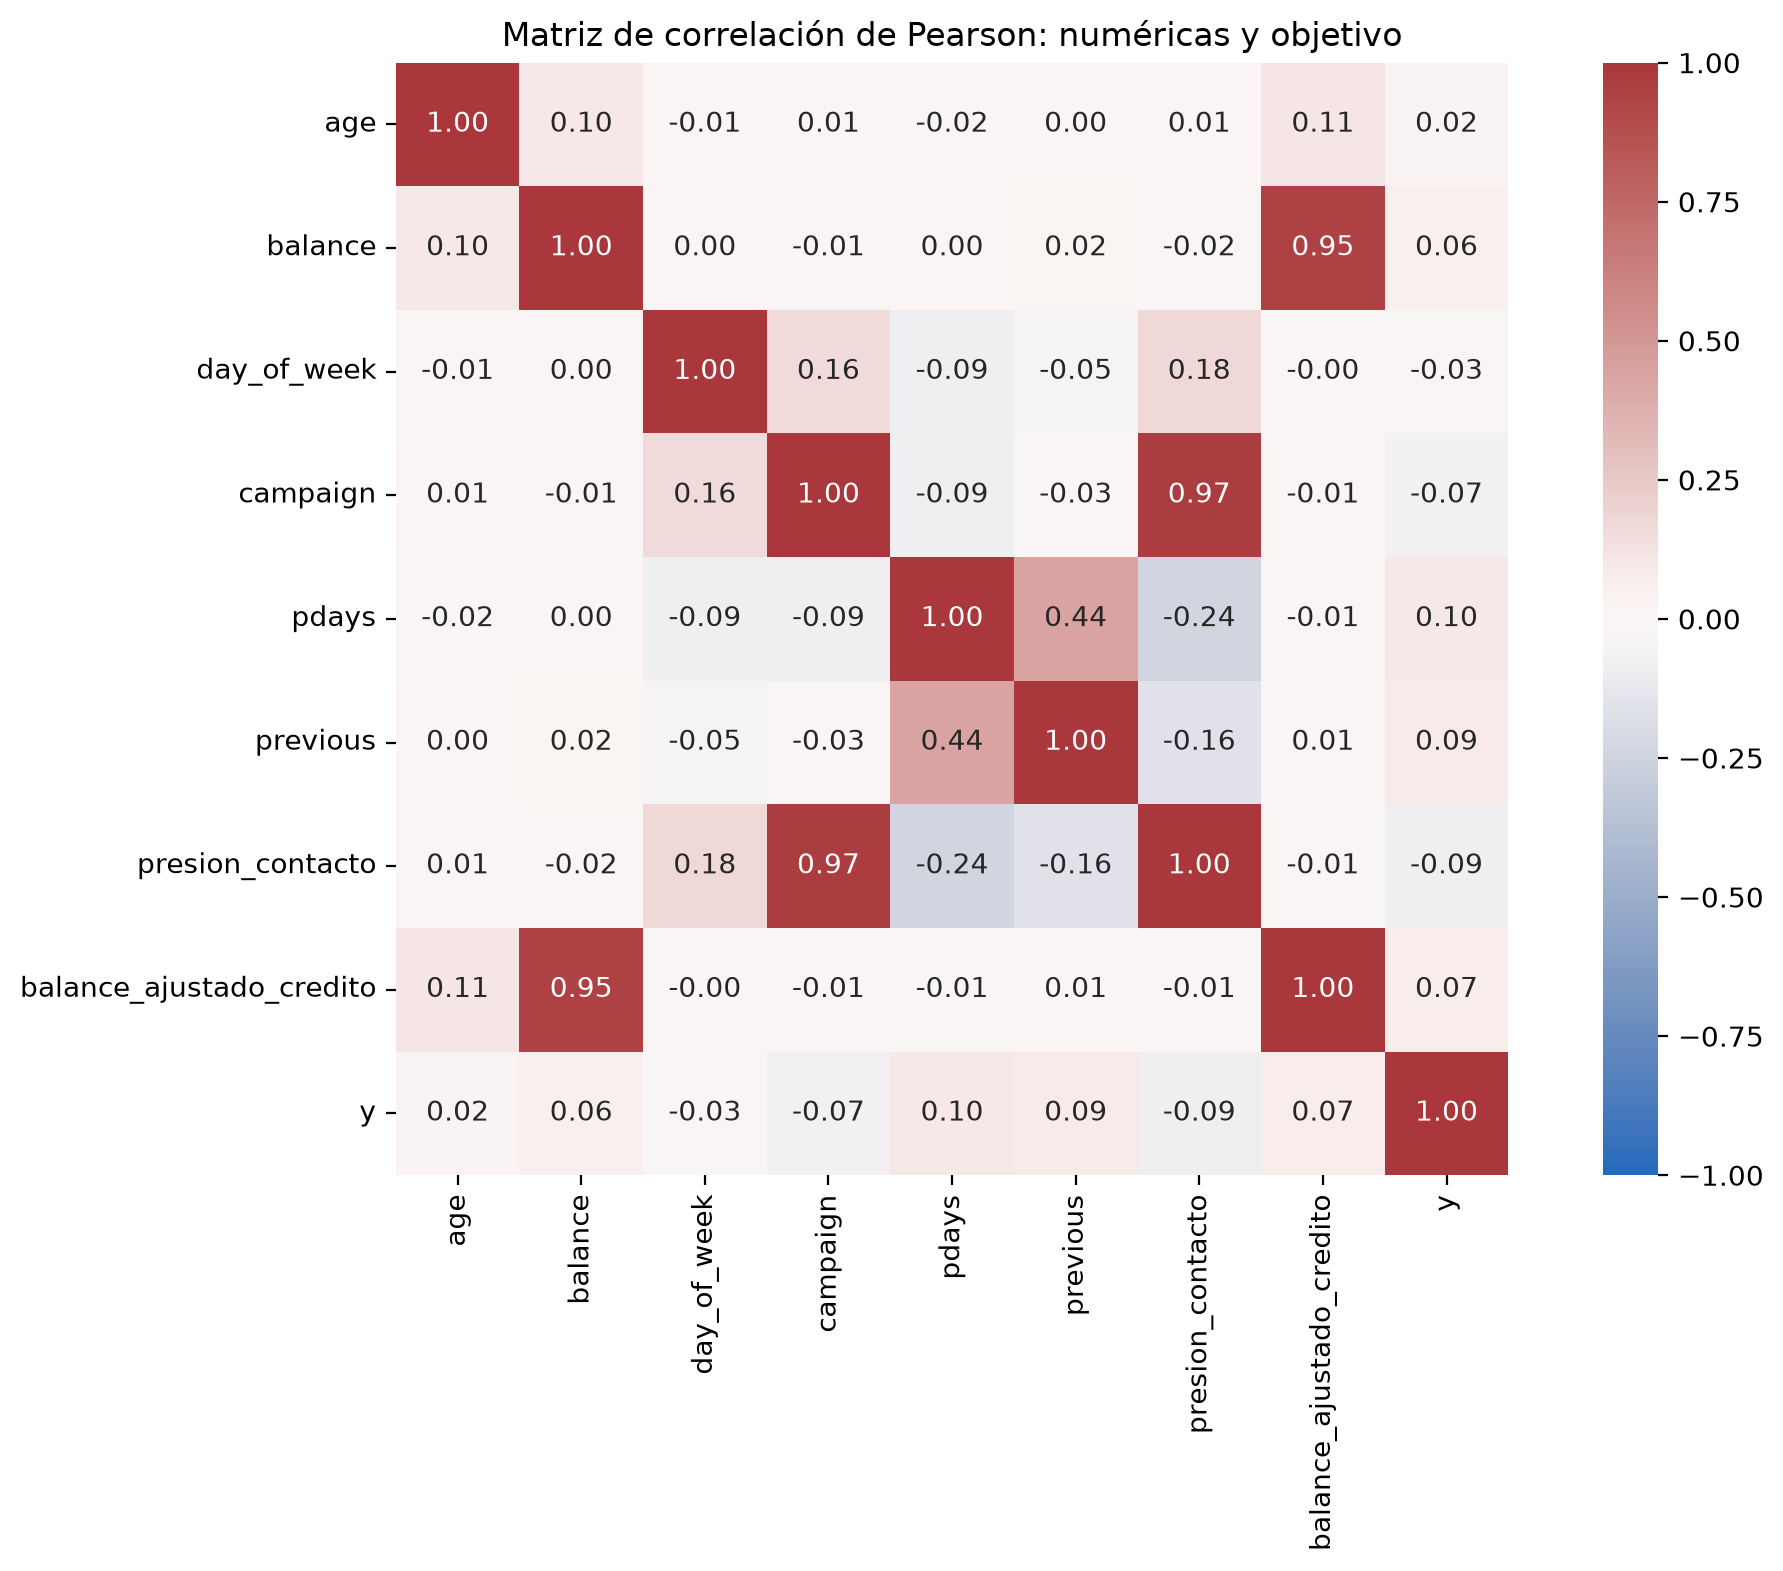

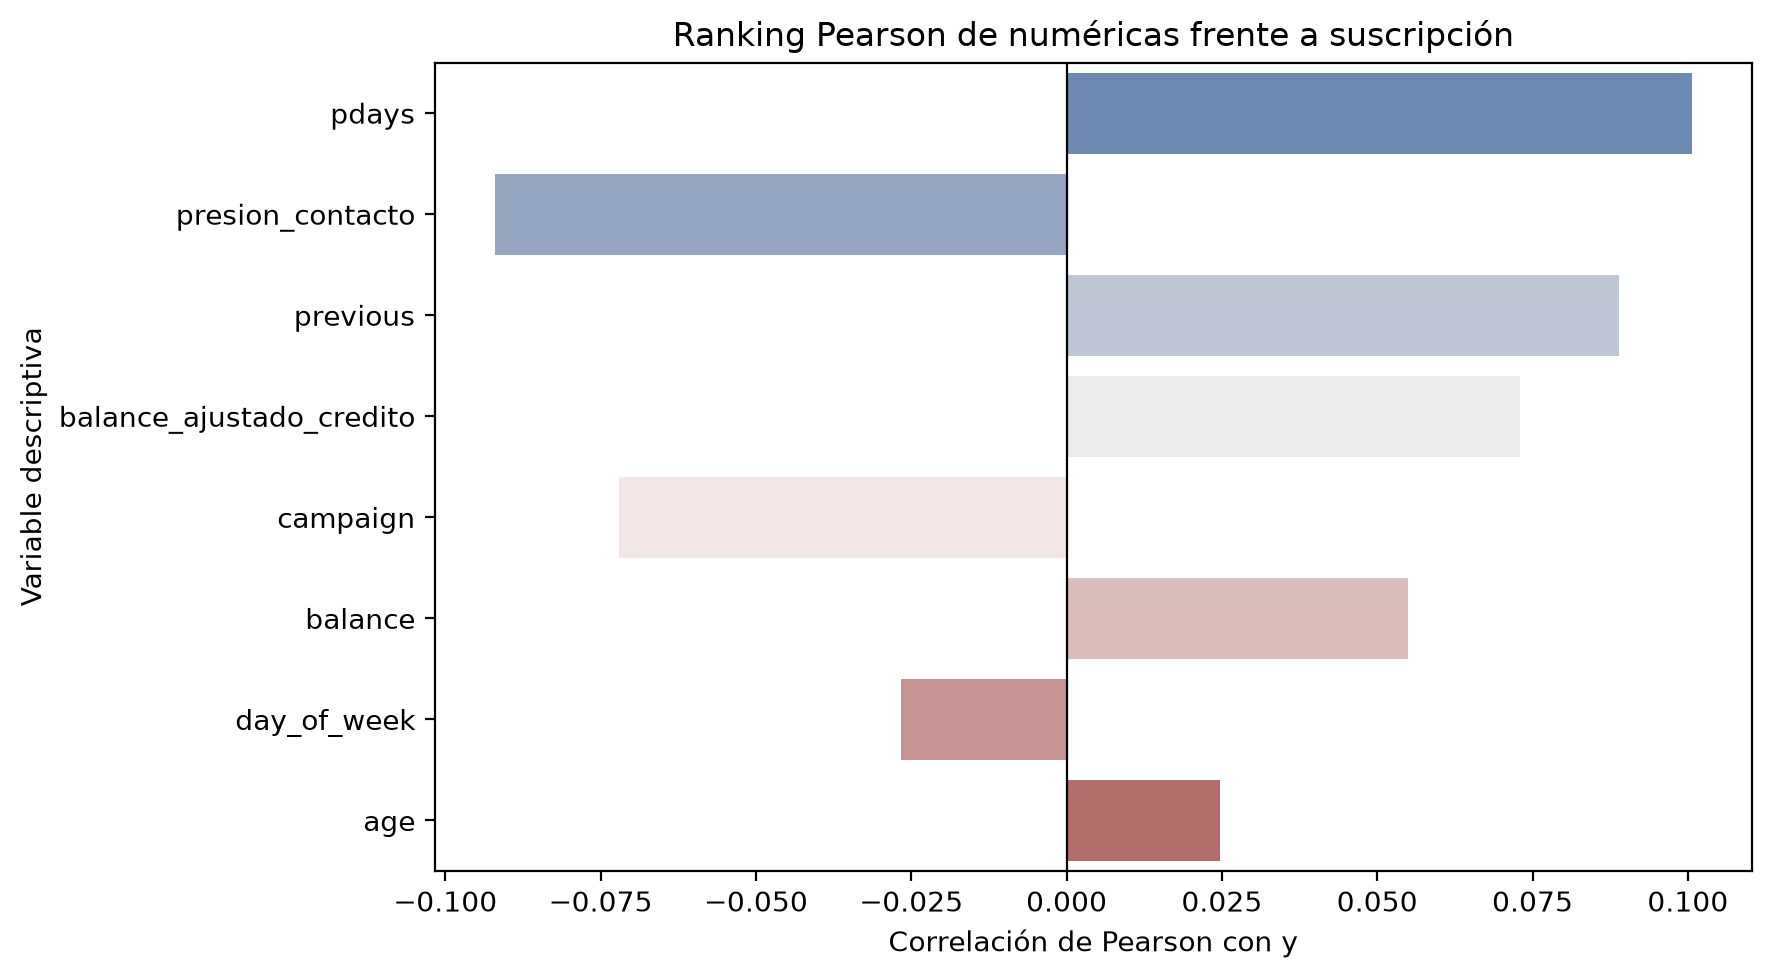

,variable,correlacion_pearson,abs_correlacion,p_valor
0,pdays,0.1007,0.1007,0.0
1,presion_contacto,-0.0921,0.0921,0.0
2,previous,0.0888,0.0888,0.0
3,balance_ajustado_credito,0.0730,0.0730,0.0
4,campaign,-0.0720,0.0720,0.0
5,balance,0.0550,0.0550,0.0
6,day_of_week,-0.0266,0.0266,0.0
7,age,0.0247,0.0247,0.0


In [ ]:
# Método 2: Pearson cuantifica la asociación lineal de cada numérica con y codificada 0/1.
_columnas_numericas_filtro = X_entrenamiento.select_dtypes(include="number").columns
_resultados_pearson = []
for _columna in _columnas_numericas_filtro:
    _correlacion, _p_valor = pearsonr(X_entrenamiento[_columna], y_entrenamiento)
    _resultados_pearson.append(
        {
            "variable": _columna,
            "correlacion_pearson": _correlacion,
            "abs_correlacion": abs(_correlacion),
            "p_valor": _p_valor,
        }
    )
ranking_pearson = (
    pd.DataFrame(_resultados_pearson)
    .sort_values("abs_correlacion", ascending=False)
    .reset_index(drop=True)
)

_matriz_pearson = X_entrenamiento[_columnas_numericas_filtro].copy()
_matriz_pearson["y"] = y_entrenamiento.to_numpy()
_fig_matriz_pearson, _eje_matriz_pearson = plt.subplots(figsize=(11, 8))
sns.heatmap(_matriz_pearson.corr(method="pearson"), cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, ax=_eje_matriz_pearson)
_eje_matriz_pearson.set_title("Matriz de correlación de Pearson: numéricas y objetivo")
_fig_matriz_pearson.tight_layout()

_fig_ranking_pearson, _eje_ranking_pearson = plt.subplots(figsize=(9, 5))
sns.barplot(data=ranking_pearson, x="correlacion_pearson", y="variable", hue="variable", legend=False, palette="vlag", ax=_eje_ranking_pearson)
_eje_ranking_pearson.axvline(0, color="black", linewidth=0.8)
_eje_ranking_pearson.set_title("Ranking Pearson de numéricas frente a suscripción")
_eje_ranking_pearson.set_xlabel("Correlación de Pearson con y")
_eje_ranking_pearson.set_ylabel("Variable descriptiva")
_fig_ranking_pearson.tight_layout()
plt.show()
ranking_pearson.round(4)

In [ ]:
principal_pearson = ranking_pearson.iloc[0]
direccion = "positiva" if principal_pearson["correlacion_pearson"] > 0 else "negativa"
mo.md(
    f"""
    **Interpretación de Pearson.** `{principal_pearson['variable']}` tiene la mayor asociación lineal
    absoluta entre las numéricas (r = **{principal_pearson['correlacion_pearson']:.3f}**, asociación
    {direccion}; p-valor = **{principal_pearson['p_valor']:.3g}**). En la matriz, los tonos cercanos
    a cero indican relaciones lineales débiles; por ello una variable puede ser útil en un modelo aun
    si no domina este ranking, especialmente si su efecto depende de otras variables.
    """
)

**Interpretación de Pearson.** `pdays` tiene la mayor asociación lineal
absoluta entre las numéricas (r = **0.101**, asociación
positiva; p-valor = **3.72e-82**). En la matriz, los tonos cercanos
a cero indican relaciones lineales débiles; por ello una variable puede ser útil en un modelo aun
si no domina este ranking, especialmente si su efecto depende de otras variables.

In [ ]:
# Comparación consolidada: cada ranking se conserva en su propia escala de asociación.
resumen_filtros = pd.concat(
    [
        ranking_chi2.assign(metodo="Chi-cuadrada", medida="V de Cramér", puntaje=ranking_chi2["v_cramer"])[["metodo", "variable", "medida", "puntaje", "p_valor"]],
        ranking_pearson.assign(metodo="Pearson", medida="abs(r)", puntaje=ranking_pearson["abs_correlacion"])[["metodo", "variable", "medida", "puntaje", "p_valor"]],
    ],
    ignore_index=True,
).sort_values(["metodo", "puntaje"], ascending=[True, False])
print("Comparación de variables descriptivas frente al objetivo, ordenada dentro de cada filtro:")
resumen_filtros.round(4)

Comparación de variables descriptivas frente al objetivo, ordenada dentro de cada filtro:


,metodo,variable,medida,puntaje,p_valor
0,Chi-cuadrada,poutcome,V de Cramér,0.4735,0.0
1,Chi-cuadrada,month,V de Cramér,0.2573,0.0
2,Chi-cuadrada,housing,V de Cramér,0.1393,0.0
3,Chi-cuadrada,job,V de Cramér,0.1383,0.0
4,Chi-cuadrada,education,V de Cramér,0.0709,0.0
...,...,...,...,...,...
12,Pearson,balance_ajustado_credito,abs(r),0.0730,0.0
13,Pearson,campaign,abs(r),0.0720,0.0
14,Pearson,balance,abs(r),0.0550,0.0
15,Pearson,day_of_week,abs(r),0.0266,0.0


## 8. Implementación de validación cruzada de 5 particiones

La selección vuelve a ajustarse dentro de cada partición: chi-cuadrada para los indicadores
categóricos codificados y Pearson para las variables numéricas escaladas. Así, cada pliegue usa
únicamente sus propios datos de entrenamiento y la validación no recibe información adelantada.
Se usa regresión logística con ponderación balanceada porque la clase positiva es minoritaria.

In [ ]:
# Se implementa Pearson como función de puntaje compatible con SelectKBest.
def puntaje_pearson(X, y):
    puntajes, p_valores = [], []
    for indice in range(X.shape[1]):
        r, p_valor = pearsonr(X[:, indice], y)
        puntajes.append(abs(r))
        p_valores.append(p_valor)
    return np.asarray(puntajes), np.asarray(p_valores)

# Cada rama aplica el filtro apropiado a su tipo de variable dentro de cada pliegue.
preprocesador_seleccion = ColumnTransformer(
    transformers=[
        (
            "numericas",
            Pipeline(
                steps=[
                    ("preparacion", transformador_numerico),
                    ("seleccion_pearson", SelectKBest(score_func=puntaje_pearson, k=6)),
                ]
            ),
            columnas_numericas,
        ),
        (
            "categoricas",
            Pipeline(
                steps=[
                    ("preparacion", transformador_categorico),
                    ("seleccion_chi2", SelectKBest(score_func=chi2, k=25)),
                ]
            ),
            columnas_categoricas,
        ),
    ],
    remainder="drop",
)
# El pipeline encapsula preparación, filtros y clasificación para impedir fuga de información.
modelo = Pipeline(
    steps=[
        ("preprocesamiento_y_seleccion", preprocesador_seleccion),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

In [ ]:
# Se usa validación cruzada estratificada de cinco particiones porque la clase positiva
# es minoritaria. Se reportan métricas que no dependen solo de la clase mayoritaria.
cv_estratificada = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes_cv = cross_validate(
    modelo,
    X_entrenamiento,
    y_entrenamiento,
    cv=cv_estratificada,
    scoring={
        "roc_auc": "roc_auc",
        "balanced_accuracy": "balanced_accuracy",
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
    },
    n_jobs=-1,
    return_train_score=False,
)
resultados_validacion = pd.DataFrame(
    {
        "métrica": ["ROC AUC", "Exactitud balanceada", "F1", "Precisión", "Sensibilidad"],
        "promedio": [
            puntajes_cv["test_roc_auc"].mean(),
            puntajes_cv["test_balanced_accuracy"].mean(),
            puntajes_cv["test_f1"].mean(),
            puntajes_cv["test_precision"].mean(),
            puntajes_cv["test_recall"].mean(),
        ],
        "desviación estándar": [
            puntajes_cv["test_roc_auc"].std(),
            puntajes_cv["test_balanced_accuracy"].std(),
            puntajes_cv["test_f1"].std(),
            puntajes_cv["test_precision"].std(),
            puntajes_cv["test_recall"].std(),
        ],
    }
).round(3)
resultados_validacion

,métrica,promedio,desviación estándar
0,ROC AUC,0.745,0.000
1,Exactitud balanceada,0.688,0.005
2,F1,0.368,0.005
3,Precisión,0.268,0.005
4,Sensibilidad,0.588,0.012


In [ ]:
# Se ajusta el modelo final solo con entrenamiento y se evalúa una única vez en prueba.
modelo.fit(X_entrenamiento, y_entrenamiento)
prediccion_prueba = modelo.predict(X_prueba)
probabilidad_prueba = modelo.predict_proba(X_prueba)[:, 1]
metricas_prueba = {
    "ROC AUC": roc_auc_score(y_prueba, probabilidad_prueba),
    "Exactitud": accuracy_score(y_prueba, prediccion_prueba),
    "Exactitud balanceada": balanced_accuracy_score(y_prueba, prediccion_prueba),
    "F1": f1_score(y_prueba, prediccion_prueba),
    "Precisión": precision_score(y_prueba, prediccion_prueba),
    "Sensibilidad": recall_score(y_prueba, prediccion_prueba),
}
print(pd.Series(metricas_prueba).round(3))
print("\nReporte de clasificación:\n")
print(classification_report(y_prueba, prediccion_prueba, target_names=["no", "sí"]))

ROC AUC                 0.752
Exactitud               0.764
Exactitud balanceada    0.689
F1                      0.369
Precisión               0.269
Sensibilidad            0.590
dtype: float64

Reporte de clasificación:

              precision    recall  f1-score   support

          no       0.94      0.79      0.86      7985
          sí       0.27      0.59      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.69      0.61      9043
weighted avg       0.86      0.76      0.80      9043



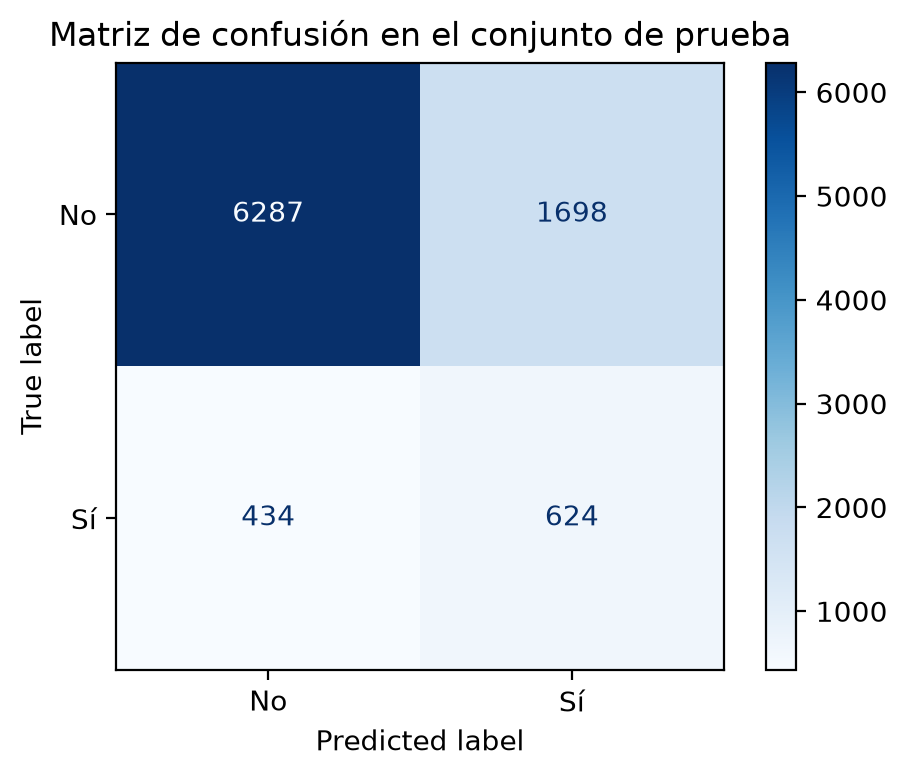

In [ ]:
# La matriz permite observar los aciertos y errores para ambas clases en prueba.
_fig_matriz_confusion, _ax_matriz_confusion = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    modelo,
    X_prueba,
    y_prueba,
    display_labels=["No", "Sí"],
    cmap="Blues",
    ax=_ax_matriz_confusion,
)
_ax_matriz_confusion.set_title("Matriz de confusión en el conjunto de prueba")
_fig_matriz_confusion.tight_layout()
plt.show()

## 9. Conclusiones

Resultados obtenidos durante la preparación de datos y las características seleccionadas.

In [ ]:
# Se construye una conclusión a partir de los valores calculados en la ejecución.
variables_chi = ", ".join(ranking_chi2.head(3)["variable"])
variables_pearson = ", ".join(ranking_pearson.head(3)["variable"])
mo.md(
    f"""
    ### Conclusión

    Se preparó el conjunto eliminando duplicados exactos, imputando las categorías faltantes
    dentro de cada partición y creando dos variables derivadas: presión de contacto y balance
    ajustado por crédito. La variable `duration` se excluyó deliberadamente: usarla daría
    un resultado poco realista porque solo se conoce cuando la llamada ya terminó.

    El ranking chi-cuadrada destacó las categóricas **{variables_chi}** y Pearson destacó las
    numéricas **{variables_pearson}**. Estos resultados se interpretan por separado porque las
    escalas de asociación son diferentes; la selección definitiva se repite dentro de cada
    partición del modelo para evitar fuga de información.

    En validación cruzada, el ROC AUC promedio fue de **{resultados_validacion.loc[0, 'promedio']:.3f}**
    y la exactitud balanceada fue de **{resultados_validacion.loc[1, 'promedio']:.3f}**. En el conjunto de
    prueba independiente, el ROC AUC fue **{metricas_prueba['ROC AUC']:.3f}**, la precisión para la clase
    positiva fue **{metricas_prueba['Precisión']:.3f}** y la sensibilidad fue
    **{metricas_prueba['Sensibilidad']:.3f}**. Por ello, el modelo puede servir para ordenar clientes
    por probabilidad de suscripción y priorizar contactos, pero el umbral de decisión debe ajustarse
    según el costo de llamar a un cliente y el valor esperado de una suscripción.
    """
)

### Conclusión

Se preparó el conjunto eliminando duplicados exactos, imputando las categorías faltantes
dentro de cada partición y creando dos variables derivadas: presión de contacto y balance
ajustado por crédito. La variable `duration` se excluyó deliberadamente: usarla daría
un resultado poco realista porque solo se conoce cuando la llamada ya terminó.

El ranking chi-cuadrada destacó las categóricas **poutcome, month, housing** y Pearson destacó las
numéricas **pdays, presion_contacto, previous**. Estos resultados se interpretan por separado porque las
escalas de asociación son diferentes; la selección definitiva se repite dentro de cada
partición del modelo para evitar fuga de información.

En validación cruzada, el ROC AUC promedio fue de **0.745**
y la exactitud balanceada fue de **0.688**. En el conjunto de
prueba independiente, el ROC AUC fue **0.752**, la precisión para la clase
positiva fue **0.269** y la sensibilidad fue
**0.590**. Por ello, el modelo puede servir para ordenar clientes
por probabilidad de suscripción y priorizar contactos, pero el umbral de decisión debe ajustarse
según el costo de llamar a un cliente y el valor esperado de una suscripción.